# Alocação de Bits da CNN1D Quantizada sob Restrições da VU13P (Lagrange/KKT)
## ATLAS L0 Ringer — topologia `v2` (25 anéis) — FPGA AMD Virtex UltraScale+ VU13P

Pipeline (detalhes e deduções em `docs/theory_and_formulation.md`):

```text
 FP32 de referência ──► Sensibilidade Ω_l(b)          (Hessiana/Hutchinson e ΔL medido, pesos e ativações)
                    └─► Custo R_j(x) na VU13P           (modelo estrutural calibrado com sínteses hls4ml+Vivado)
                              │
                              ▼
       min Ω(x)  s.a.  g_j(x) = (R_j(x) − B_j)/B_j ≤ 0,  j ∈ {DSP, LUT, FF}
         (a) relaxação contínua: water-filling KKT (bisseção × Newton)
         (b) problema discreto: enumeração exata (ótimo global)
         (c) decomposição dual lagrangiana: preços-sombra μ_j, limites e certificado KKT
                              │
                              ▼
 Fronteira Ω*(B_LUT) ──► QAT (warm-start) dos candidatos ──► SP medido ──► escolha final
                              │
                              ▼
 Validação cruzada K=5 sem vazamento + holdout com limiar fixado na validação
```

Artefatos no padrão **Jubiaba**: `<export_dir>/<dataset_prefix>/<model_name>/iet{iet}/ieta{ieta}/v{version}/`.


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import sys
import json
import dataclasses
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras as keras
import qkeras
from scipy.stats import spearmanr
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_curve, auc

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(repo_root, 'src')):
    repo_root = os.path.abspath(os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from src.metrics import CONFIG_VERSOES, slice_rings_by_version, norm1, compute_sp_with_threshold
from src.models import COMPUTE_LAYERS, ACTIVATION_LAYERS
from src.hardware import (
    VU13P_CHIP_LIMITS, get_vu13p_budget, get_cost_model, layer_specs_from_model,
    layer_input_bits, compute_model_hardware_costs,
)
from src.sensitivity import (
    compute_hutchinson_hessian_trace, compute_activation_hessian_traces, weight_quantization_errors,
    activation_quantization_errors, omega_table, monotone_table, measure_ptq_loss_increase,
    compute_layer_c_coefficients,
)
from src.kkt_allocator import (
    solve_kkt_bit_allocation, linear_cost_coefficients, build_choice_groups, solve_exact,
    LagrangianDualAllocator, budget_frontier,
)
from src.training import train_fp32, train_qat, evaluate_at_threshold
from src.exporter import ArtifactExporter
from src.visualization import (
    plot_rings_profile, plot_learning_curves, plot_best_model_roc, plot_cv_roc_envelope,
    plot_output_score_histogram, plot_confusion_matrix_knee, plot_cv_statistics_boxplots,
    plot_fa_per_fold_workpoints, plot_roc_duel_fp32_vs_kkt, plot_vu13p_resource_utilization,
    plot_primal_dual_kkt_evolution, plot_sensitivity_validation, plot_pareto_frontier,
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
pd.set_option("display.width", 200)
print("TensorFlow:", tf.__version__, "| QKeras:", qkeras.__version__)


TensorFlow: 2.20.0 | QKeras: 0.9.0


## 1. Dados `v2`, espaço de decisão e orçamento da instância na VU13P

O orçamento por instância é derivado de parâmetros de sistema explícitos,
$B_j = f_{\text{disp}} \cdot B_{j,\text{chip}} / N_{\text{inst}}$: $N_{\text{inst}}$ cópias do classificador
dividem a fração $f_{\text{disp}}$ do FPGA. **Os valores abaixo são uma hipótese ilustrativa** e devem ser
fixados com o projeto do firmware L0; a Seção 5 mostra a solução para vários orçamentos, de modo que as
conclusões não dependem de um único número. A BRAM não entra como restrição: em `io_parallel` os pesos
são constantes na lógica e a única RAM usada é a tabela da sigmoide (1 RAMB18, constante).


,Recurso,VU13P (chip),B_j (instância)
0,DSP,"12,288",73.7
1,LUT,"1,728,000","10,368.0"
2,FF,"3,456,000","20,736.0"


Eventos balanceados: 77,126 | estrutura v2: {'PS': 2, 'EM1': 16, 'EM2': 2, 'EM3': 2, 'HAD1': 1, 'HAD2': 1, 'HAD3': 1}


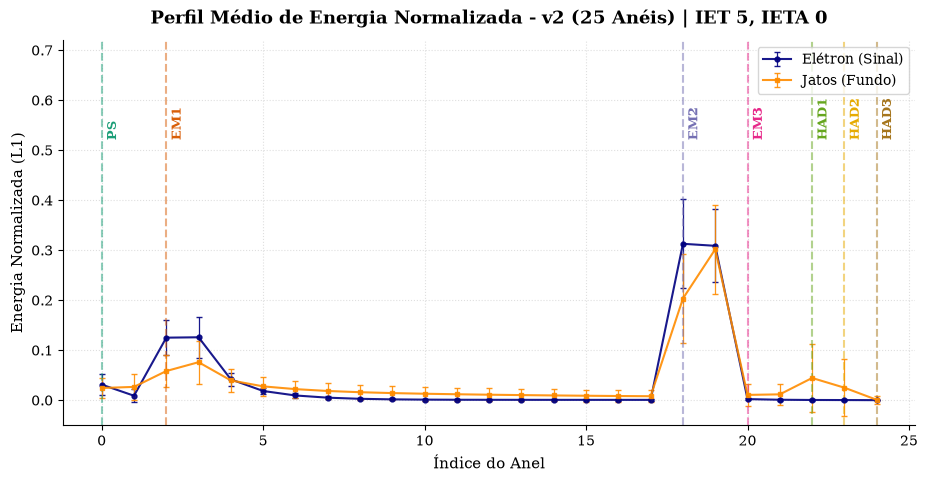

Desenvolvimento (61700, 25) (treino (49360, 25), validação (12340, 25)) | holdout (15426, 25)


In [2]:
EXPORT_DIR = os.path.join(repo_root, "results")
DATA_DIR = os.environ.get("RINGER_DATA_DIR", os.path.join(repo_root, "data"))
DATASET_PREFIX = "mc21_13p6TeV.Zee.JF17.2sigma.5M"
MODEL_NAME = "QCNN1D_KKT"
IET, IETA, VERSION = 5, 0, 2
N_SPLITS = 5
EPOCHS = 18

INPUT_BITS = 8                                   # anéis normalizados em ufixed<8,0> na entrada do FPGA
BIT_OPTIONS = [2, 3, 4, 5, 6, 7, 8, 10, 12, 16]  # w_l e a_l candidatos
N_INSTANCES, DEVICE_FRACTION = 100, 0.6          # HIPÓTESE ILUSTRATIVA de sistema
SP_TOL = 0.001                                   # diferenças de SP abaixo disso são tratadas como empate

cfg = CONFIG_VERSOES[VERSION]
arch = {"input_dim": cfg["input_dim"], "filters": cfg["filters"], "kernel": cfg["kernel"], "dense_units": cfg["dense_units"]}
B = get_vu13p_budget(n_instances=N_INSTANCES, device_fraction=DEVICE_FRACTION)
display(pd.DataFrame([{"Recurso": k, "VU13P (chip)": f"{VU13P_CHIP_LIMITS[k]:,.0f}", "B_j (instância)": f"{B[k]:,.1f}"} for k in B]))

exporter = ArtifactExporter(export_dir=EXPORT_DIR, dataset_prefix=DATASET_PREFIX, model_name=MODEL_NAME,
                            iet=IET, ieta=IETA, version=VERSION)

df_loaded = pd.read_hdf(os.path.join(DATA_DIR, f"{DATASET_PREFIX}.et{IET}_eta{IETA}.h5"), key="data")
ring_columns = sorted([c for c in df_loaded.columns if c.startswith("trig_L2_cl_ring_")], key=lambda x: int(x.split("_")[-1]))
signal_df = df_loaded[df_loaded["target"] == 1][ring_columns]
background_df = df_loaded[df_loaded["target"] == 0][ring_columns]
ns = min(len(signal_df), len(background_df))
sig_sliced, estrutura_v = slice_rings_by_version(signal_df.values[:ns], VERSION)
bkg_sliced, _ = slice_rings_by_version(background_df.values[:ns], VERSION)
sig_normed, bkg_normed = norm1(sig_sliced), norm1(bkg_sliced)
print(f"Eventos balanceados: {2 * ns:,} | estrutura v{VERSION}: {estrutura_v}")

plot_rings_profile(sig_normed=sig_normed, bkg_normed=bkg_normed, estrutura=estrutura_v, version=VERSION, iet=IET,
                   ieta=IETA, save_path=exporter.get_plot_path(f"rings_profile_v{VERSION}.png"), show=True)

X_all = np.vstack([sig_normed, bkg_normed]).astype(np.float32)
y_all = np.concatenate([np.ones(ns, dtype=np.float32), np.zeros(ns, dtype=np.float32)])
X_dev, X_holdout, y_dev, y_holdout = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
X_tr_ref, X_val_ref, y_tr_ref, y_val_ref = train_test_split(X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=SEED)
print(f"Desenvolvimento {X_dev.shape} (treino {X_tr_ref.shape}, validação {X_val_ref.shape}) | holdout {X_holdout.shape}")


## 2. Referência FP32

Treinada em `X_tr_ref`; o limiar de decisão é escolhido no joelho do SP em `X_val_ref` e **aplicado** ao
holdout (sem reotimizar o limiar no conjunto de teste).


In [3]:
model_fp32, cb_fp32, hist_fp32 = train_fp32(arch, X_tr_ref, y_tr_ref, X_val_ref, y_val_ref, epochs=EPOCHS, seed=SEED)
ho_fp32 = evaluate_at_threshold(model_fp32, X_holdout, y_holdout, cb_fp32.best_threshold)
print(f"FP32 | SP val = {cb_fp32.best_sp*100:.2f}% | holdout (limiar da validação): SP = {ho_fp32['sp']*100:.2f}%, "
      f"PD = {ho_fp32['pd']*100:.2f}%, FA = {ho_fp32['fa']*100:.2f}%")


E0000 00:00:1794325281.757889 1185154 cuda_executor.cc:1309] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
****************************************************************************
* hwloc 2.0.3 received invalid information from the operating system.
*
* Failed with: intersection without inclusion
* while inserting Group0 (P#16 cpuset 0x000003c0) at L1d (P#16 cpuset 0x00000044)
* coming from: linux:sysfs:cluster
*
* The following FAQ entry in the hwloc documentation may help:
*   What should I do when hwloc reports "operating system" warnings?
* Otherwise please report this error message to the hwloc user's mailing list,
* along with the files generated by the hwloc-gather-topology script.
* 
* hwloc will now ignore this invalid topology information and continue.
****************************************************************************
W0000 00:00:1794325

FP32 | SP val = 97.80% | holdout (limiar da validação): SP = 97.81%, PD = 98.85%, FA = 3.23%


## 3. Sensibilidade à quantização $\Omega_l(b)$

Para cada tensor $T_l$ (pesos das 3 camadas e ativações ReLU de `conv1d_1`/`dense_1`):

$$\Omega_l(b) = \tfrac{1}{2}\,\frac{\operatorname{Tr}(\mathbf{H}_{ll})}{n_l}\,\big\|Q_b(T_l) - T_l\big\|_2^2$$

com $\operatorname{Tr}(\mathbf{H}_{ll})$ estimado por Hutchinson (bloco a bloco) e $Q_b$ **o quantizador QKeras
efetivamente treinado**. Comparamos com o aumento de perda **medido** ao quantizar só aquele tensor
(PTQ, validação inteira). As duas tabelas são usadas como objetivo e comparadas no laço com QAT.


Tr(H) pesos: {'conv1d_1': 0.9696, 'dense_1': 2.4504, 'output_dense': 0.01}
Tr(H) ativações (traço, n_entradas): {'conv1d_1': (39.633, 819200), 'dense_1': (0.74, 32768)}
Spearman Ω_Hessiana × ΔL medido (b ≤ 8): todos = 0.745 | 4 ≤ b ≤ 8 = 0.517


bits,2,3,4,5,6,7,8
tensor,,,,,,,
a:conv1d_1,1.87,1.87,1.92,14.50,0.75,1.40,-0.42
a:dense_1,0.02,0.13,0.03,-0.01,0.00,0.00,-0.00
w:conv1d_1,10.95,8.61,0.11,0.27,-0.47,0.43,-3.85
w:dense_1,69.57,76.27,1.07,1.43,3.89,1.03,-0.25
w:output_dense,3.09,3.09,-2.91,1.21,6.56,-55.05,75.35


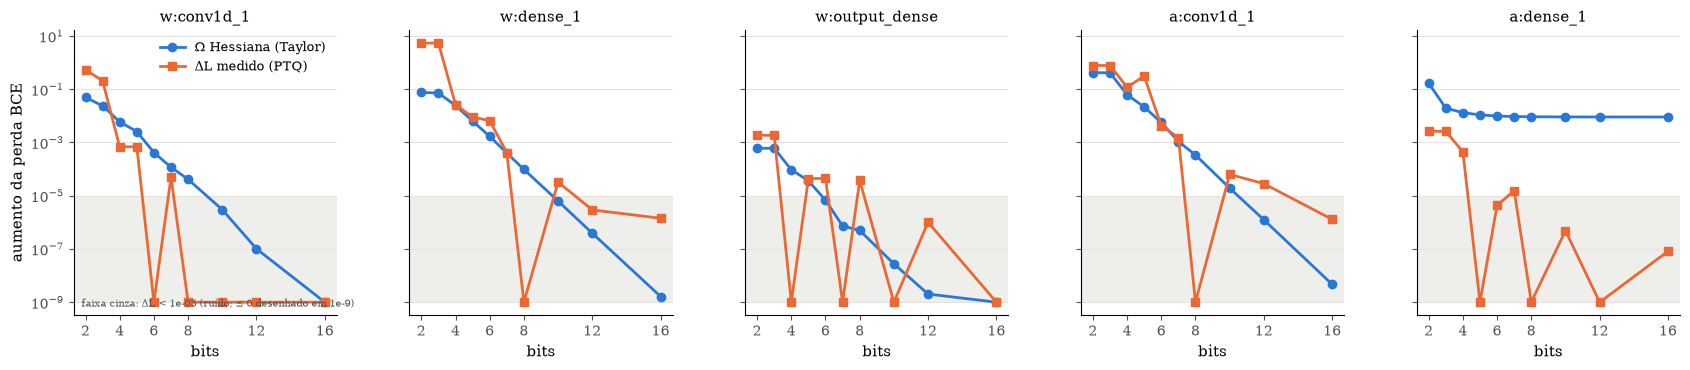

'/home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/plots/sensitivity_validation.png'

In [4]:
bce = keras.losses.BinaryCrossentropy()
calib_idx = np.random.default_rng(SEED).choice(len(X_val_ref), size=4096, replace=False)
x_cal = tf.constant(X_val_ref[calib_idx])
y_cal = tf.constant(y_val_ref[calib_idx][:, None])

w_traces = compute_hutchinson_hessian_trace(model_fp32, bce, x_cal, y_cal, num_hvp=32, seed=SEED)
a_traces = compute_activation_hessian_traces(model_fp32, bce, x_cal, y_cal, ACTIVATION_LAYERS, num_hvp=32, seed=SEED)
w_sizes = {l.name: int(l.kernel.numpy().size) for l in model_fp32.layers if getattr(l, "kernel", None) is not None}

omega_hess_w = omega_table(w_traces, w_sizes, weight_quantization_errors(model_fp32, BIT_OPTIONS))
omega_hess_a = omega_table({k: v[0] for k, v in a_traces.items()}, {k: v[1] for k, v in a_traces.items()},
                           activation_quantization_errors(model_fp32, x_cal, BIT_OPTIONS, ACTIVATION_LAYERS))
measured = measure_ptq_loss_increase(model_fp32, bce, tf.constant(X_val_ref), tf.constant(y_val_ref[:, None]),
                                     BIT_OPTIONS, COMPUTE_LAYERS, ACTIVATION_LAYERS)
omega_meas_w, omega_meas_a = monotone_table(measured["weights"]), monotone_table(measured["activations"])
OBJECTIVES = {"hessian": (omega_hess_w, omega_hess_a), "measured": (omega_meas_w, omega_meas_a)}

print("Tr(H) pesos:", {k: round(v, 4) for k, v in w_traces.items()})
print("Tr(H) ativações (traço, n_entradas):", {k: (round(v[0], 3), v[1]) for k, v in a_traces.items()})

hess_all = {**{f"w:{k}": v for k, v in omega_hess_w.items()}, **{f"a:{k}": v for k, v in omega_hess_a.items()}}
meas_all = {**{f"w:{k}": v for k, v in measured["weights"].items()}, **{f"a:{k}": v for k, v in measured["activations"].items()}}
# Acima de 8 bits o ΔL medido fica abaixo da resolução da avaliação (~1e-5) e a razão é ruído: tabela em b <= 8.
sens_rows = [{"tensor": t, "bits": b, "Omega_hessiana": hess_all[t][b], "dL_medido": meas_all[t][b],
              "razao_medido/hessiana": meas_all[t][b] / max(hess_all[t][b], 1e-30)} for t in hess_all for b in BIT_OPTIONS if b <= 8]
df_sens = pd.DataFrame(sens_rows)
rho_all = float(spearmanr(df_sens["Omega_hessiana"], df_sens["dL_medido"]).correlation)
rho_hi = float(spearmanr(df_sens[df_sens.bits >= 4]["Omega_hessiana"], df_sens[df_sens.bits >= 4]["dL_medido"]).correlation)
print(f"Spearman Ω_Hessiana × ΔL medido (b ≤ 8): todos = {rho_all:.3f} | 4 ≤ b ≤ 8 = {rho_hi:.3f}")
display(df_sens.pivot(index="tensor", columns="bits", values="razao_medido/hessiana").round(2))
plot_sensitivity_validation(hess_all, meas_all, save_path=exporter.get_plot_path("sensitivity_validation.png"), show=True)


## 4. Custo calibrado na VU13P

Modelo estrutural de `src/hardware.py` (somadores por neurônio com pesos constantes; zeros e potências de 2
gratuitos; multiplicadores largos e não triviais em DSP), ajustado por mínimos quadrados nas sínteses
hls4ml → Vitis HLS → Vivado (place & route) de `src/calibration/vu13p_hls4ml_synthesis.json`.
O custo de cada candidato é previsto **antes do QAT** quantizando os pesos FP32 (PTQ).

A precisão esperada é o erro *leave-one-out* (LOO) da calibração. Para que um candidato previsto como
viável o seja na síntese, as restrições usam o orçamento efetivo $B_j^{\text{ef}} = B_j/(1+m_j)$, em que
$m_j$ é a pior subestimação LOO do recurso $j$ (restrição robusta à incerteza do modelo).


In [5]:
cost_model = get_cost_model()
print(f"β_LUT = {cost_model.beta_lut:.4f} LUT/bit-de-somador | γ_LUT = {cost_model.gamma_lut:.3f} LUT/bit-de-ReLU | "
      f"β_FF = {cost_model.beta_ff:.4f} | δ_FF = {cost_model.delta_ff:.2f} FF/DSP | γ_FF = {cost_model.gamma_ff:.0f}")
display(pd.DataFrame(cost_model.calibration_table()).round(3))
MARGIN = cost_model.margins
B_EFF = {r: B[r] / (1.0 + MARGIN[r]) for r in B}
display(pd.DataFrame([{"Recurso": r, "B_j": round(B[r], 1), "margem m_j (pior LOO)": f"{100*MARGIN[r]:.1f}%",
                       "B_j efetivo": round(B_EFF[r], 1)} for r in B]))

_ptq_specs = {w: {s.name: s for s in layer_specs_from_model(model_fp32, {n: w for n in COMPUTE_LAYERS}, 8, INPUT_BITS)}
              for w in BIT_OPTIONS}
_cost_cache = {}


def layer_cost(name, w_bits, a_in_bits):
    key = (name, int(w_bits), int(a_in_bits))
    if key not in _cost_cache:
        # replace() keeps every other field of the spec (kernel, positions, relu_after, ...)
        spec = dataclasses.replace(_ptq_specs[int(w_bits)][name], w_bits=int(w_bits), a_in_bits=int(a_in_bits))
        _cost_cache[key] = cost_model.layer_resources(spec)
    return _cost_cache[key]


OVERHEAD = cost_model.overhead


def config_cost(w_bits, a_bits):
    a_in = layer_input_bits(COMPUTE_LAYERS, a_bits, INPUT_BITS)
    tot = {r: OVERHEAD[r] for r in ("DSP", "LUT", "FF")}
    for n in COMPUTE_LAYERS:
        for r in tot:
            tot[r] += layer_cost(n, w_bits[n], a_in[n])[r]
    return tot


def config_omega(objective, w_bits, a_bits):
    ow, oa = OBJECTIVES[objective]
    return sum(ow[n][w_bits[n]] for n in COMPUTE_LAYERS) + sum(oa[m][a_bits[m]] for m in ACTIVATION_LAYERS)


def is_feasible(cost):
    return all(cost[r] <= B_EFF[r] for r in B_EFF)


groups = {obj: build_choice_groups(COMPUTE_LAYERS, ACTIVATION_LAYERS, ow, oa, layer_cost, BIT_OPTIONS, BIT_OPTIONS,
                                   input_bits=INPUT_BITS) for obj, (ow, oa) in OBJECTIVES.items()}

REFERENCES = {
    "u8 (8 bits uniforme)": ({n: 8 for n in COMPUTE_LAYERS}, {m: 8 for m in ACTIVATION_LAYERS}),
    "KKT antigo [2,5,8]/[8,8]": ({"conv1d_1": 2, "dense_1": 5, "output_dense": 8}, {m: 8 for m in ACTIVATION_LAYERS}),
    "u16": ({n: 16 for n in COMPUTE_LAYERS}, {m: 16 for m in ACTIVATION_LAYERS}),
}
ref_rows = []
for label, (wb, ab) in REFERENCES.items():
    c = config_cost(wb, ab)
    ref_rows.append({"configuração": label, **{f"{r} estimado": round(c[r]) for r in ("DSP", "LUT", "FF")},
                     "Ω hessiana": config_omega("hessian", wb, ab), "Ω medido": config_omega("measured", wb, ab),
                     "viável em B": is_feasible(c)})
display(pd.DataFrame(ref_rows))


β_LUT = 0.3945 LUT/bit-de-somador | γ_LUT = 1.326 LUT/bit-de-ReLU | β_FF = 0.1705 | δ_FF = 6.44 FF/DSP | γ_FF = 956


,point,in_domain,DSP_measured,DSP_predicted,DSP_rel_err,DSP_loo_rel_err,LUT_measured,LUT_predicted,LUT_rel_err,LUT_loo_rel_err,FF_measured,FF_predicted,FF_rel_err,FF_loo_rel_err
0,u16,True,1241.0,1245.0,0.003,0.003,29571.0,29456.778,-0.004,-0.009,17629.0,17629.140,0.000,0.267
1,u8,True,0.0,0.0,0.000,0.000,23309.0,23401.600,0.004,0.022,9002.0,8903.254,-0.011,-0.277
2,kkt,True,0.0,0.0,0.000,0.000,6923.0,8363.390,0.208,0.246,2984.0,3104.380,0.040,0.062
3,kkt_pf1,False,0.0,0.0,0.000,NaN,14589.0,4683.715,-0.679,NaN,15792.0,2834.264,-0.821,NaN
4,mp_v1,True,7.0,8.0,0.143,0.143,7785.0,7320.229,-0.060,-0.088,2962.0,2594.937,-0.124,-0.218
5,mp_b10k,True,10.0,8.0,-0.200,-0.200,12011.0,11355.206,-0.055,-0.062,3870.0,4215.289,0.089,0.121


,Recurso,B_j,margem m_j (pior LOO),B_j efetivo
0,DSP,73.7,20.0%,61.4
1,LUT,10368.0,8.8%,9529.0
2,FF,20736.0,27.7%,16243.1


,configuração,DSP estimado,LUT estimado,FF estimado,Ω hessiana,Ω medido,viável em B
0,u8 (8 bits uniforme),0,22752,8623,0.009648,0.000133,False
1,"KKT antigo [2,5,8]/[8,8]",0,8447,3141,0.065118,0.549534,True
2,u16,1222,25177,16548,0.008985,0.000003,False


## 5. Otimização restrita: KKT, ótimo discreto e decomposição dual

**(a) Relaxação contínua (water-filling).** Só pesos, ativações fixas em 8 bits, custo de LUT linearizado
por camada ($R_l(w) \approx p_l + q_l w$) e $\Omega_l \approx c_l 4^{-w}$ com $c_l = \operatorname{Tr}(\mathbf{H}_l)\,\kappa^2/24$.
Comparamos bisseção e Newton em $t=\log_2\lambda$ e a solução arredondada com o ótimo discreto do mesmo subproblema.

**(b) Problema completo** (pesos e ativações, DSP/LUT/FF): enumeração exata dos $10 \times 10^2 \times 10^2$ candidatos.

**(c) Decomposição dual**: $x(\mu)=\arg\min_x \Omega(x)+\sum_j \mu_j g_j(x)$ separável por grupo;
$\mu_j \leftarrow \max(0, \mu_j + \eta_t g_j)$ (passo de Polyak). Fornece limite inferior $q(\mu)\le\Omega^*$,
o melhor primal viável e o gap de dualidade; o certificado KKT (viabilidade + folga complementar) só é
declarado quando realmente vale.


,método,iterações,λ*,b_conv1d_1 contínuo,b_dense_1 contínuo,b_output_dense contínuo,b_conv1d_1 inteiro,b_dense_1 inteiro,b_output_dense inteiro
0,water-filling (bisection),31,0.000013,3.839,4.365,3.591,4,4,8
1,water-filling (newton),4,0.000013,3.839,4.365,3.591,4,4,8


c_l (sem fator n_l): {'conv1d_1': 2.5856, 'dense_1': 6.5344, 'output_dense': 0.0266}
Resíduos KKT (contínuo): {'conv1d_1': {'bound': 'interior', 'stationarity_residual': -6.938893903907228e-18}, 'dense_1': {'bound': 'interior', 'stationarity_residual': 3.469446951953614e-18}, 'output_dense': {'bound': 'interior', 'stationarity_residual': 5.421010862427522e-20}}
Arredondado {'conv1d_1': 4, 'dense_1': 4, 'output_dense': 8}: Ω = 0.03986, custo real do modelo {'DSP': 0, 'LUT': 7298, 'FF': 2419}, viável = True
Ótimo discreto do mesmo subproblema: {'conv1d_1': 4, 'dense_1': 5, 'output_dense': 4}  Ω = 0.02177  LUT = 9522
[hessian] dual: LB = 0.02147 ≤ Ω* = 0.02177 ≤ UB = 0.02177 (gap 1.3%), 319 iterações (dual_stalled), μ = {'DSP': 0.0, 'LUT': 0.02806, 'FF': 0.0}, 15,896/100,000 viáveis


[measured] dual: LB = 0.00967 ≤ Ω* = 0.009699 ≤ UB = 0.009699 (gap 0.3%), 500 iterações (max_iter), μ = {'DSP': 0.0, 'LUT': 0.0196, 'FF': 0.0}, 15,896/100,000 viáveis


,objetivo,método,w,a,Ω,DSP,LUT,FF,tempo [s]
0,hessian,exato (enumeração),"[4, 5, 4]","[8, 8]",0.021767,0,9522,3376,0.001
1,hessian,dual + heurística,"[4, 5, 4]","[8, 8]",0.021767,0,9522,3376,0.040
2,measured,exato (enumeração),"[4, 5, 12]","[8, 5]",0.009699,8,9522,3428,0.001
3,measured,dual + heurística,"[4, 5, 12]","[8, 5]",0.009699,8,9522,3428,0.153


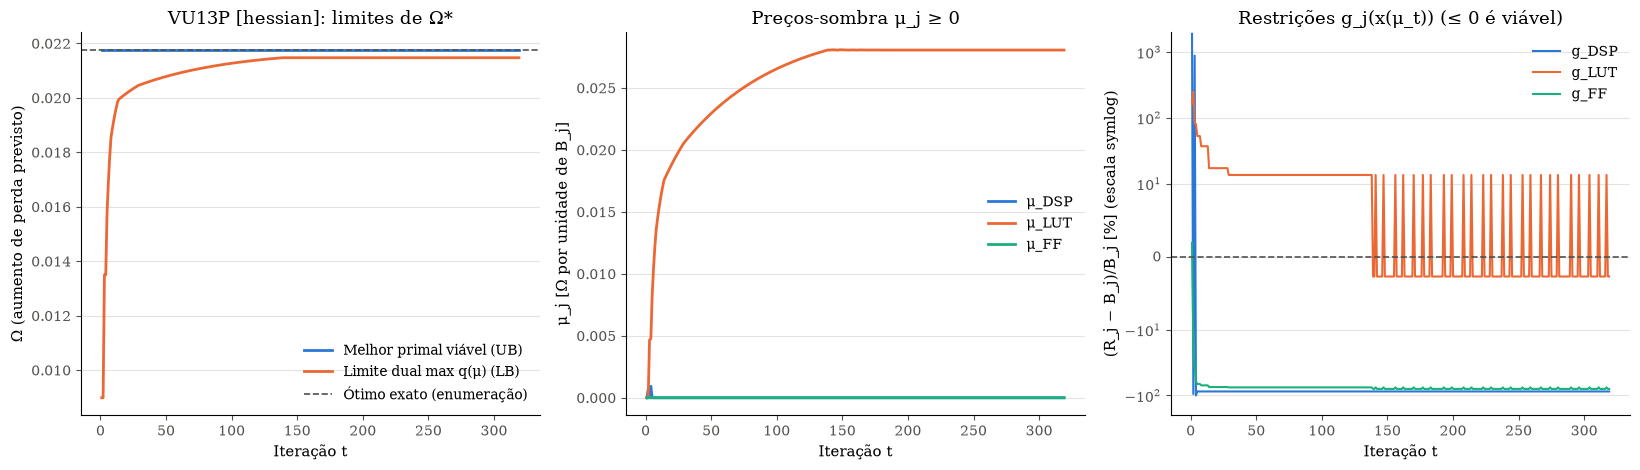

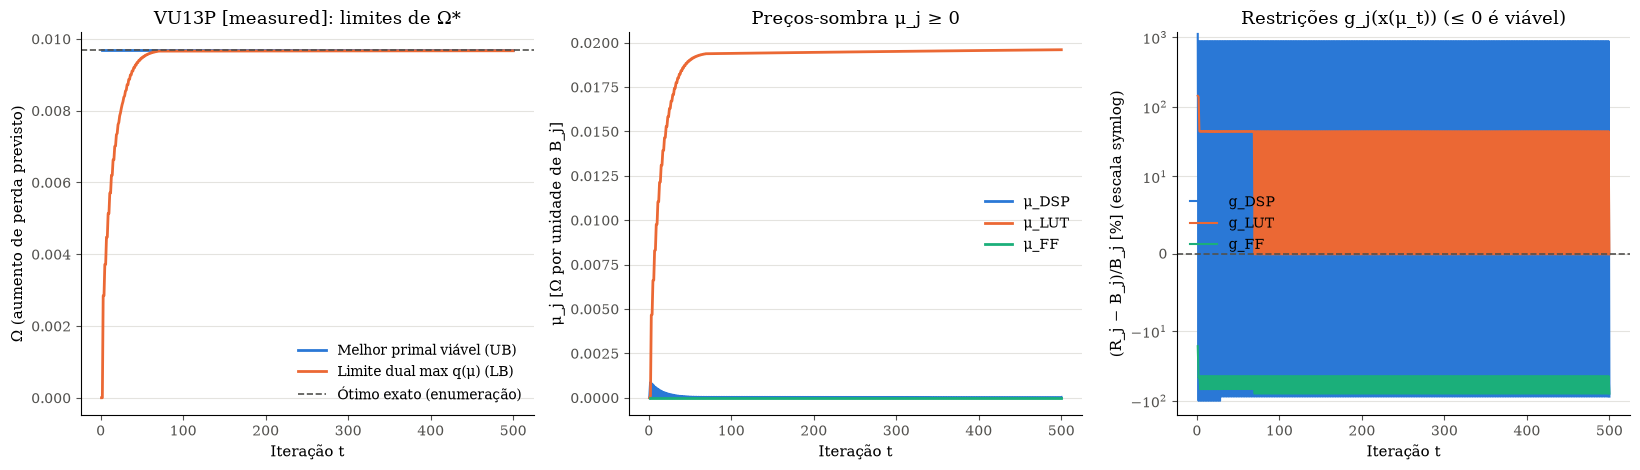

In [6]:
# (a) relaxação contínua
W_CONT = [b for b in BIT_OPTIONS if b <= 8]
A8 = {m: 8 for m in ACTIVATION_LAYERS}
a_in_8 = layer_input_bits(COMPUTE_LAYERS, A8, INPUT_BITS)
c_l = compute_layer_c_coefficients(model_fp32, w_traces)
lin = {n: linear_cost_coefficients(layer_cost, n, W_CONT, a_in_8[n], "LUT") for n in COMPUTE_LAYERS}
B_w = B_EFF["LUT"] - OVERHEAD["LUT"] - sum(p for p, _ in lin.values())
wf = {m: solve_kkt_bit_allocation(list(COMPUTE_LAYERS), [c_l[n] for n in COMPUTE_LAYERS], [lin[n][1] for n in COMPUTE_LAYERS],
                                  B_w, b_min=min(W_CONT), b_max=max(W_CONT), method=m) for m in ("bisection", "newton")}
groups_w8 = build_choice_groups(COMPUTE_LAYERS, ACTIVATION_LAYERS, omega_hess_w, omega_hess_a, layer_cost, W_CONT, W_CONT,
                                input_bits=INPUT_BITS, fixed_a_bits=A8)
exact_w8 = solve_exact(groups_w8, B_EFF, OVERHEAD)
wf_int_cost = config_cost(wf["newton"]["integer_bits"], A8)
display(pd.DataFrame([
    {"método": f"water-filling ({m})", "iterações": wf[m]["iterations"], "λ*": wf[m]["lambda_optimal"],
     **{f"b_{n} contínuo": round(wf[m]["continuous_bits"][n], 3) for n in COMPUTE_LAYERS},
     **{f"b_{n} inteiro": wf[m]["integer_bits"][n] for n in COMPUTE_LAYERS}} for m in wf]))
print("c_l (sem fator n_l):", {k: round(v, 4) for k, v in c_l.items()})
print("Resíduos KKT (contínuo):", wf["newton"]["kkt"])
print(f"Arredondado {wf['newton']['integer_bits']}: Ω = {config_omega('hessian', wf['newton']['integer_bits'], A8):.4g}, "
      f"custo real do modelo {({k: round(v) for k, v in wf_int_cost.items()})}, viável = {is_feasible(wf_int_cost)}")
print(f"Ótimo discreto do mesmo subproblema: {exact_w8['w_bits']}  Ω = {exact_w8['omega']:.4g}  LUT = {exact_w8['resources']['LUT']:.0f}")

# (b) + (c) problema completo
opt = {}
rows = []
for obj, G in groups.items():
    t0 = time.perf_counter(); ex = solve_exact(G, B_EFF, OVERHEAD); t_ex = time.perf_counter() - t0
    alloc = LagrangianDualAllocator(G, B_EFF, OVERHEAD)
    t0 = time.perf_counter(); du = alloc.solve(max_iter=500); t_du = time.perf_counter() - t0
    opt[obj] = {"exact": ex, "dual": du, "history": alloc.history}
    for meth, s, tt in (("exato (enumeração)", ex, t_ex), ("dual + heurística", du, t_du)):
        rows.append({"objetivo": obj, "método": meth, "w": [s["w_bits"][n] for n in COMPUTE_LAYERS],
                     "a": [s["a_bits"][m] for m in ACTIVATION_LAYERS], "Ω": s["omega"],
                     **{r: round(s["resources"][r]) for r in ("DSP", "LUT", "FF")}, "tempo [s]": round(tt, 3)})
    print(f"[{obj}] dual: LB = {du['lower_bound']:.4g} ≤ Ω* = {ex['omega']:.4g} ≤ UB = {du['upper_bound']:.4g} "
          f"(gap {100*du['relative_gap']:.1f}%), {du['iterations']} iterações ({du['stop_reason']}), "
          f"μ = { {k: round(v, 5) for k, v in du['mu'].items()} }, {ex['n_feasible']:,}/{ex['n_candidates']:,} viáveis")
display(pd.DataFrame(rows))

for obj in opt:
    plot_primal_dual_kkt_evolution(opt[obj]["history"], save_path=exporter.get_plot_path(
        "kkt_primal_dual_evolution.png" if obj == "hessian" else f"kkt_primal_dual_evolution_{obj}.png"),
        exact_optimum=opt[obj]["exact"]["omega"], title_prefix=f"VU13P [{obj}]", show=True)


## 6. Ciclo fechado com QAT: fronteira $\Omega^*(B_{\text{LUT}})$ → SP medido (triagem)

O proxy $\Omega$ descreve a degradação **antes** do QAT; o QAT recupera parte dela. Por isso o laço não
confia só no proxy: resolvemos o problema exato para vários $B_{\text{LUT}}$ (fronteira), treinamos com QAT
(*warm-start* do FP32) cada solução distinta e as configurações uniformes de referência, e medimos o SP de
validação. O custo usado na decisão é recalculado com os **pesos após o QAT** (zeros e dígitos CSD mudam
durante o treino, sobretudo em ≤ 4 bits).

Uma única partição de validação não separa candidatos a menos de ~0,1–0,3 p.p. (ruído de treino), então
esta etapa é só **triagem**: vão para a Seção 7 os até `MAX_SHORTLIST` candidatos viáveis com SP a menos de
`SCREEN_TOL` do melhor.


/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


  w=[3, 3, 2] a=[7, 10]: SP val = 97.69% | LUT ≈ 5,653 (previsto antes do QAT 5,509) | ['hessian@B_LUT=6000'] (4s)


/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


  w=[4, 4, 16] a=[8, 16]: SP val = 97.67% | LUT ≈ 7,466 (previsto antes do QAT 7,259) | ['hessian@B_LUT=8000'] (2s)


  w=[4, 5, 4] a=[8, 8]: SP val = 97.67% | LUT ≈ 9,730 (previsto antes do QAT 9,522) | ['hessian@B_LUT=10368'] (2s)


  w=[5, 6, 16] a=[7, 16]: SP val = 97.66% | LUT ≈ 13,220 (previsto antes do QAT 12,728) | ['hessian@B_LUT=14000'] (3s)


... (12 outputs left out)

  w=[5, 5, 5] a=[5, 5]: SP val = 96.18% | LUT ≈ 11,109 (previsto antes do QAT 10,595) | ['uniforme u5'] (4s)


  w=[6, 6, 6] a=[6, 6]: SP val = 97.28% | LUT ≈ 14,071 (previsto antes do QAT 13,875) | ['uniforme u6'] (4s)


  w=[8, 8, 8] a=[8, 8]: SP val = 97.83% | LUT ≈ 23,402 (previsto antes do QAT 22,752) | ['uniforme u8'] (3s)


  w=[2, 5, 8] a=[8, 8]: SP val = 97.65% | LUT ≈ 8,363 (previsto antes do QAT 8,447) | ['KKT antigo'] (3s)


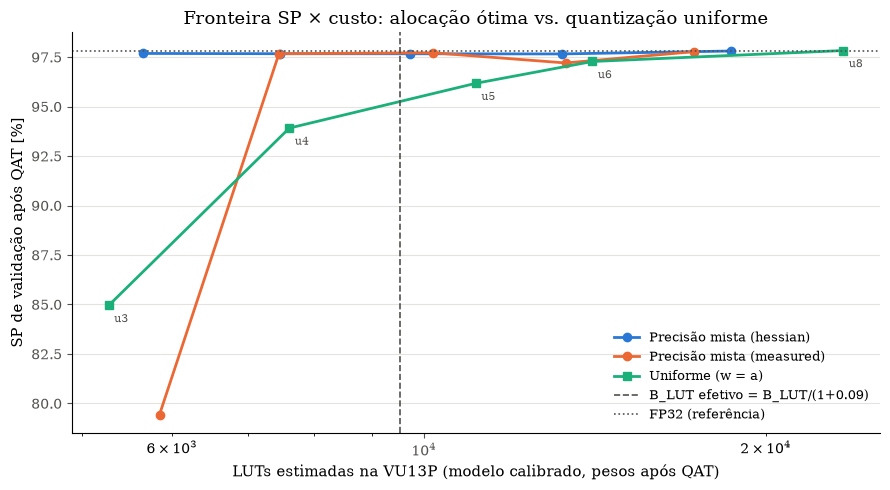

Erro da previsão de LUT antes do QAT: mediana -2.9%, pior 12.7%
Spearman (Ω do candidato × perda de SP após QAT): {'hessian': 0.67, 'measured': 0.654}

Lista curta para a CV (4 candidatos viáveis a ≤ 0.2 p.p. do melhor):


,w,a,fontes,sp_val,DSP,LUT,FF,LUT_prev_PTQ,Ω_hessian,Ω_measured,viável
0,"[3, 3, 2]","[7, 10]",hessian@B_LUT=6000,0.97687,0.0,5653.13751,1831.98866,5509.34023,0.10546,5.63999,True
1,"[4, 4, 16]","[8, 16]",hessian@B_LUT=8000,0.97673,8.0,7466.06225,2543.35217,7258.55232,0.03967,0.02684,True
6,"[4, 4, 16]","[8, 12]",measured@B_LUT=8000,0.97673,8.0,7453.43807,2537.89529,7245.92814,0.03968,0.02684,True
15,"[2, 5, 8]","[8, 8]",KKT antigo,0.97649,0.0,8363.38978,3104.37988,8447.22222,0.06512,0.54953,True


,w,a,fontes,sp_val,DSP,LUT,FF,LUT_prev_PTQ,Ω_hessian,Ω_measured,viável
10,"[3, 3, 3]","[3, 3]",uniforme u3,0.84951,0.0,5277.55008,1687.97815,5114.22477,0.52657,6.41126,True
0,"[3, 3, 2]","[7, 10]",hessian@B_LUT=6000,0.97687,0.0,5653.13751,1831.98866,5509.34023,0.10546,5.63999,True
5,"[2, 4, 12]","[4, 8]",measured@B_LUT=6000,0.79439,8.0,5850.81043,2092.73315,5511.73289,0.14417,0.87764,True
6,"[4, 4, 16]","[8, 12]",measured@B_LUT=8000,0.97673,8.0,7453.43807,2537.89529,7245.92814,0.03968,0.02684,True
1,"[4, 4, 16]","[8, 16]",hessian@B_LUT=8000,0.97673,8.0,7466.06225,2543.35217,7258.55232,0.03967,0.02684,True
11,"[4, 4, 4]","[4, 4]",uniforme u4,0.93915,0.0,7612.20845,2573.35713,6646.65605,0.10472,0.33831,True
15,"[2, 5, 8]","[8, 8]",KKT antigo,0.97649,0.0,8363.38978,3104.37988,8447.22222,0.06512,0.54953,True
2,"[4, 5, 4]","[8, 8]",hessian@B_LUT=10368,0.97671,0.0,9729.88772,3465.81299,9522.37779,0.02177,0.00973,False
7,"[4, 5, 12]","[8, 5]",measured@B_LUT=10368,0.97721,8.0,10189.28946,3715.89952,9522.18053,0.02324,0.00970,False
12,"[5, 5, 5]","[5, 5]",uniforme u5,0.96178,0.0,11109.27750,3961.19549,10595.03948,0.04101,0.32073,False


In [7]:
LUT_SWEEP = sorted({4000.0, 6000.0, 8000.0, float(round(B["LUT"])), 14000.0, 20000.0})
SCREEN_TOL, MAX_SHORTLIST = 0.002, 4
candidates = {}


def register(w_bits, a_bits, source):
    key = (tuple(w_bits[n] for n in COMPUTE_LAYERS), tuple(a_bits[m] for m in ACTIVATION_LAYERS))
    candidates.setdefault(key, {"w_bits": dict(w_bits), "a_bits": dict(a_bits), "sources": []})["sources"].append(source)


for obj, G in groups.items():
    for nominal, sol in zip(LUT_SWEEP, budget_frontier(G, B_EFF, OVERHEAD, "LUT", [v / (1 + MARGIN["LUT"]) for v in LUT_SWEEP])):
        if sol["feasible"]:
            register(sol["w_bits"], sol["a_bits"], f"{obj}@B_LUT={nominal:.0f}")
for b in (3, 4, 5, 6, 8):
    register({n: b for n in COMPUTE_LAYERS}, {m: b for m in ACTIVATION_LAYERS}, f"uniforme u{b}")
register(*REFERENCES["KKT antigo [2,5,8]/[8,8]"], "KKT antigo")

qat_rows = []
for key, cand in candidates.items():
    t0 = time.perf_counter()
    q_c, cb, _ = train_qat(arch, cand["w_bits"], cand["a_bits"], INPUT_BITS, model_fp32, X_tr_ref, y_tr_ref,
                           X_val_ref, y_val_ref, epochs=EPOCHS, seed=SEED)
    cost_ptq = config_cost(cand["w_bits"], cand["a_bits"])            # previsão antes do QAT (proposta)
    cost = compute_model_hardware_costs(q_c, weights_bits=cand["w_bits"], act_bits=cand["a_bits"],
                                        input_bits=INPUT_BITS)["vu13p_resources"]  # com os pesos treinados
    qat_rows.append({"w": list(key[0]), "a": list(key[1]), "fontes": "; ".join(cand["sources"]),
                     "sp_val": cb.best_sp, **{r: cost[r] for r in ("DSP", "LUT", "FF")}, "LUT_prev_PTQ": cost_ptq["LUT"],
                     "Ω_hessian": config_omega("hessian", cand["w_bits"], cand["a_bits"]),
                     "Ω_measured": config_omega("measured", cand["w_bits"], cand["a_bits"]),
                     "viável": is_feasible(cost), "_key": key})
    print(f"  w={list(key[0])} a={list(key[1])}: SP val = {cb.best_sp*100:.2f}% | LUT ≈ {cost['LUT']:,.0f} "
          f"(previsto antes do QAT {cost_ptq['LUT']:,.0f}) | "
          f"{cand['sources']} ({time.perf_counter() - t0:.0f}s)")
df_qat = pd.DataFrame(qat_rows)

frontier_plot = pd.concat([
    df_qat[df_qat["fontes"].str.contains(f"{obj}@")].assign(objective=obj) for obj in OBJECTIVES])
uniform_plot = df_qat[df_qat["fontes"].str.contains("uniforme")].assign(
    bits=lambda d: d["w"].apply(lambda w: w[0]))
plot_pareto_frontier(frontier_plot, uniform_plot, lut_budget=B_EFF["LUT"], fp32_sp=cb_fp32.best_sp,
                     budget_label=f"B_LUT efetivo = B_LUT/(1+{MARGIN['LUT']:.2f})",
                     save_path=exporter.get_plot_path("pareto_sp_vs_lut.png"), show=True)

rho = {obj: float(spearmanr(df_qat[f"Ω_{obj}"], 1 - df_qat["sp_val"]).correlation) for obj in OBJECTIVES}
err_ptq = (df_qat["LUT_prev_PTQ"] - df_qat["LUT"]) / df_qat["LUT"]
print(f"Erro da previsão de LUT antes do QAT: mediana {100*err_ptq.median():+.1f}%, pior {100*err_ptq.abs().max():.1f}%")
print("Spearman (Ω do candidato × perda de SP após QAT):", {k: round(v, 3) for k, v in rho.items()})

feas = df_qat[df_qat["viável"]].sort_values("sp_val", ascending=False)
shortlist = feas[feas["sp_val"] >= feas["sp_val"].iloc[0] - SCREEN_TOL].head(MAX_SHORTLIST)
print(f"\nLista curta para a CV ({len(shortlist)} candidatos viáveis a ≤ {100*SCREEN_TOL:.1f} p.p. do melhor):")
display(shortlist.drop(columns="_key").round(5))
display(df_qat.drop(columns="_key").sort_values("LUT").round(5))


## 7. Decisão por validação cruzada ($K=5$) sem vazamento, e holdout

Em cada fold o FP32 de *warm-start* é treinado **apenas com o treino do fold** (antes, o warm-start global
já tinha visto os dados de validação dos folds). Nos mesmos folds treinamos os candidatos da lista curta e as
referências FP32 e 8 bits uniforme, o que permite comparar por **diferenças pareadas**. A configuração final
é a de menor custo (LUT médio entre folds, todos os folds viáveis em $B^{\text{ef}}$) cuja diferença pareada
média em relação ao melhor candidato é ≥ −`SP_TOL`. O limiar do holdout vem da validação do melhor fold.


In [8]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
short_keys = list(shortlist["_key"])
runs = {k: [] for k in short_keys}  # per candidate, per fold: metrics, model, history, predictions
ref_rows = []

for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(X_dev, y_dev), start=1):
    X_tr_f, y_tr_f, X_val_f, y_val_f = X_dev[tr_idx], y_dev[tr_idx], X_dev[val_idx], y_dev[val_idx]
    fp32_f, cb_fp32_f, _ = train_fp32(arch, X_tr_f, y_tr_f, X_val_f, y_val_f, epochs=EPOCHS, seed=SEED + fold_idx)
    _, cb_u8_f, _ = train_qat(arch, *REFERENCES["u8 (8 bits uniforme)"], INPUT_BITS, fp32_f, X_tr_f, y_tr_f,
                              X_val_f, y_val_f, epochs=EPOCHS, seed=SEED + fold_idx)
    ref_rows.append({"fold": fold_idx, "sp_fp32_ref": cb_fp32_f.best_sp, "sp_u8_ref": cb_u8_f.best_sp})
    for k in short_keys:
        wb, ab = candidates[k]["w_bits"], candidates[k]["a_bits"]
        q_f, cb_f, hist_f = train_qat(arch, wb, ab, INPUT_BITS, fp32_f, X_tr_f, y_tr_f, X_val_f, y_val_f,
                                      epochs=EPOCHS, seed=SEED + fold_idx)
        y_val_pred = q_f.predict(X_val_f, batch_size=4096, verbose=0).ravel()
        sp_f, pd_f, fa_f, thr_f, _ = compute_sp_with_threshold(y_val_f, y_val_pred)
        fa_c, pd_c, _ = roc_curve(y_val_f, y_val_pred)
        res_f = compute_model_hardware_costs(q_f, weights_bits=wb, act_bits=ab, input_bits=INPUT_BITS)["vu13p_resources"]
        runs[k].append({"fold": fold_idx, "sp": sp_f, "pd": pd_f, "fa": fa_f, "thr": thr_f, "auc": float(auc(fa_c, pd_c)),
                        "best_epoch": cb_f.best_epoch + 1, "res": res_f, "model": q_f, "history": hist_f,
                        "y_val": y_val_f, "y_pred": y_val_pred})
    print(f"  [Fold {fold_idx}/{N_SPLITS}] FP32 {cb_fp32_f.best_sp*100:.2f}% | u8 {cb_u8_f.best_sp*100:.2f}% | " +
          " | ".join(f"{list(k[0])}/{list(k[1])} {runs[k][-1]['sp']*100:.2f}%" for k in short_keys))

refs = pd.DataFrame(ref_rows)
sel_rows = []
for k in short_keys:
    sp = np.array([r["sp"] for r in runs[k]])
    lut = np.array([r["res"]["LUT"] for r in runs[k]])
    ok = all(is_feasible(r["res"]) for r in runs[k])
    sel_rows.append({"w": list(k[0]), "a": list(k[1]), "_key": k, "sp_cv_mean": sp.mean(), "sp_cv_std": sp.std(ddof=1),
                     "dif_vs_u8_pp": 100 * (sp - refs["sp_u8_ref"].values).mean(),
                     "dif_vs_fp32_pp": 100 * (sp - refs["sp_fp32_ref"].values).mean(),
                     "LUT_medio": lut.mean(), "LUT_max": lut.max(), "viável_todos_folds": ok, "_sp": sp})
df_sel = pd.DataFrame(sel_rows)
viable = df_sel[df_sel["viável_todos_folds"]]
best_cv = viable.loc[viable["sp_cv_mean"].idxmax()]
viable = viable.assign(dif_vs_melhor_pp=[100 * (s - best_cv["_sp"]).mean() for s in viable["_sp"]],
                       ep_dif_vs_melhor_pp=[100 * (s - best_cv["_sp"]).std(ddof=1) / np.sqrt(len(s)) for s in viable["_sp"]])
choice = viable[viable["dif_vs_melhor_pp"] >= -100 * SP_TOL].sort_values("LUT_medio").iloc[0]
display(viable.drop(columns=["_key", "_sp"]).round(4))

final_key = choice["_key"]
final_w, final_a = candidates[final_key]["w_bits"], candidates[final_key]["a_bits"]
final_row = df_qat[df_qat["_key"].apply(lambda k: k == final_key)].iloc[0]
final_runs = runs[final_key]
print(f"\nEscolha final: w = {final_w}, a = {final_a} | CV {choice['sp_cv_mean']*100:.2f} ± {choice['sp_cv_std']*100:.2f}% | "
      f"diferença pareada vs melhor da lista {choice['dif_vs_melhor_pp']:+.3f} p.p. | LUT médio ≈ {choice['LUT_medio']:,.0f}")

training_results_metadata, cv_records, folds_y_true, folds_y_pred = [], [], [], []
for r, ref in zip(final_runs, ref_rows):
    path_f = exporter.save_fold_model(r["model"], fold=r["fold"], repeat=1)
    rec = {"fold": r["fold"], "repeat": 1, "sp_max": r["sp"], "pd_knee": r["pd"], "fa_knee": r["fa"],
           "threshold_knee": r["thr"], "auc": r["auc"], "best_epoch": r["best_epoch"], "model_path": os.path.basename(path_f),
           "sp_fp32_ref": ref["sp_fp32_ref"], "sp_u8_ref": ref["sp_u8_ref"], "lut_estimated": r["res"]["LUT"]}
    cv_records.append(rec)
    training_results_metadata.append({**{k: v for k, v in rec.items() if k != "sp_max"}, "max_sp": r["sp"],
                                      "keras_history": r["history"]})
    folds_y_true.append(r["y_val"])
    folds_y_pred.append(r["y_pred"])
cv_df = pd.DataFrame(cv_records)
b_run = max(final_runs, key=lambda r: r["sp"])
best = {"sp": b_run["sp"], "fold": b_run["fold"], "model": b_run["model"], "history": b_run["history"], "threshold": b_run["thr"]}

print(f"CV ({N_SPLITS} folds): SP = {cv_df['sp_max'].mean()*100:.2f}% ± {cv_df['sp_max'].std()*100:.2f}% | "
      f"PD = {cv_df['pd_knee'].mean()*100:.2f}% | FA = {cv_df['fa_knee'].mean()*100:.2f}%")
for ref in ("sp_fp32_ref", "sp_u8_ref"):
    d = 100 * (cv_df["sp_max"] - cv_df[ref])
    print(f"  diferença pareada final − {ref[3:-4]}: {d.mean():+.3f} ± {d.std():.3f} p.p. (média ± desvio entre folds; "
          f"erro padrão {d.std() / np.sqrt(len(d)):.3f})")
print(f"  LUT estimadas por fold (pesos de cada fold): {cv_df['lut_estimated'].min():,.0f} – {cv_df['lut_estimated'].max():,.0f} "
      f"(B_LUT = {B['LUT']:,.0f}, efetivo {B_EFF['LUT']:,.0f})")

best_qmodel = best["model"]
ho_q = evaluate_at_threshold(best_qmodel, X_holdout, y_holdout, best["threshold"])
y_pred_holdout = ho_q["y_pred"]
hw_final = compute_model_hardware_costs(best_qmodel, weights_bits=final_w, act_bits=final_a, input_bits=INPUT_BITS)
hw_u8 = compute_model_hardware_costs(model_fp32, weights_bits={n: 8 for n in COMPUTE_LAYERS}, act_bits=8, input_bits=INPUT_BITS)
print(f"\n[Holdout — fold #{best['fold']}, limiar da validação {best['threshold']:.4f}] SP = {ho_q['sp']*100:.2f}% | "
      f"PD = {ho_q['pd']*100:.2f}% | FA = {ho_q['fa']*100:.2f}%  (SP no joelho do próprio holdout, otimista: "
      f"{ho_q['sp_knee_optimistic']*100:.2f}%)")
print(f"  Recursos estimados na VU13P: { {k: round(v, 1) for k, v in hw_final['vu13p_resources'].items()} } | BOPs = {hw_final['total_bops']:,}")

kkt_result = {
    "final": {"w_bits": final_w, "a_bits": final_a, "input_bits": INPUT_BITS,
              "estimated_resources": hw_final["vu13p_resources"], "sp_val_closed_loop": float(final_row["sp_val"]),
              "selection_rule": (f"triagem: viáveis com SP_val >= melhor - {SCREEN_TOL} (até {MAX_SHORTLIST}); decisão: menor "
                                 f"LUT médio na CV com diferença pareada vs melhor >= -{SP_TOL}"),
              "sources": final_row["fontes"]},
    "cv_selection": viable.drop(columns=["_key", "_sp"]).to_dict("records"),
    "budget": B, "budget_assumption": {"n_instances": N_INSTANCES, "device_fraction": DEVICE_FRACTION},
    "cost_margins_loo": MARGIN, "effective_budget": B_EFF,
    "bit_options": BIT_OPTIONS,
    "optimization": {obj: {"exact": {k: v for k, v in o["exact"].items() if k != "indices"},
                           "dual": o["dual"]} for obj, o in opt.items()},
    "water_filling": {"c_coefficients": c_l, "linear_lut_cost": lin, "bisection": wf["bisection"], "newton": wf["newton"],
                      "exact_discrete_same_subproblem": {k: v for k, v in exact_w8.items() if k != "indices"}},
    "sensitivity": {"hessian_trace_weights": w_traces, "hessian_trace_activations": {k: v[0] for k, v in a_traces.items()},
                    "omega_hessian": hess_all, "dL_measured": meas_all,
                    "spearman_all_bits": rho_all, "spearman_b_ge_4": rho_hi},
    "closed_loop_candidates": df_qat.drop(columns="_key").to_dict("records"),
    "cross_validation": {"sp_final": cv_df["sp_max"].tolist(), "sp_fp32_ref": cv_df["sp_fp32_ref"].tolist(),
                         "sp_u8_ref": cv_df["sp_u8_ref"].tolist(), "lut_estimated_per_fold": cv_df["lut_estimated"].tolist()},
    "spearman_omega_vs_sp_loss": rho,
    "cost_model": {"beta_lut": cost_model.beta_lut, "gamma_lut": cost_model.gamma_lut, "beta_ff": cost_model.beta_ff,
                   "delta_ff": cost_model.delta_ff, "gamma_ff": cost_model.gamma_ff, "margins": MARGIN,
                   "calibration": cost_model.calibration_table()},
    "primal_dual_history": opt["hessian"]["history"],
}
exporter.save_best_model(best_qmodel, input_dim=arch["input_dim"])
exporter.save_history(best["history"])
exporter.save_evaluation_splits(X_holdout, y_holdout, y_pred_holdout, threshold=best["threshold"])
exporter.save_metadata(
    training_results=training_results_metadata, cv_df=cv_df, kkt_result=kkt_result,
    extra_config={"rings_structure": estrutura_v, "vu13p_chip_limits": VU13P_CHIP_LIMITS, "vu13p_instance_budget": B,
                  "hardware_u8_reference": hw_u8, "hardware_qkeras_kkt": hw_final,
                  "holdout_metrics": {"sp": ho_q["sp"], "pd": ho_q["pd"], "fa": ho_q["fa"], "threshold": best["threshold"],
                                      "sp_knee_optimistic": ho_q["sp_knee_optimistic"],
                                      "fp32_sp": ho_fp32["sp"], "fp32_pd": ho_fp32["pd"], "fp32_fa": ho_fp32["fa"]}},
    seed=SEED,
)


/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


  [Fold 1/5] FP32 97.61% | u8 97.69% | [3, 3, 2]/[7, 10] 97.10% | [4, 4, 16]/[8, 16] 97.60% | [4, 4, 16]/[8, 12] 97.60% | [2, 5, 8]/[8, 8] 97.45%


/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer HeNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


... (14 outputs left out)

,w,a,sp_cv_mean,sp_cv_std,dif_vs_u8_pp,dif_vs_fp32_pp,LUT_medio,LUT_max,viável_todos_folds,dif_vs_melhor_pp,ep_dif_vs_melhor_pp
0,"[3, 3, 2]","[7, 10]",0.9734,0.0029,-0.3829,-0.2778,5719.5328,6001.6832,True,-0.3196,0.0554
1,"[4, 4, 16]","[8, 16]",0.9765,0.0024,-0.0669,0.0382,8053.4811,8553.7141,True,-0.0036,0.0041
2,"[4, 4, 16]","[8, 12]",0.9766,0.0024,-0.0633,0.0418,8178.8549,8588.6279,True,0.0000,0.0000
3,"[2, 5, 8]","[8, 8]",0.9748,0.0016,-0.2402,-0.1351,8611.5732,9221.0449,True,-0.1769,0.0501



Escolha final: w = {'conv1d_1': 4, 'dense_1': 4, 'output_dense': 16}, a = {'conv1d_1': 8, 'dense_1': 16} | CV 97.65 ± 0.24% | diferença pareada vs melhor da lista -0.004 p.p. | LUT médio ≈ 8,053
CV (5 folds): SP = 97.65% ± 0.24% | PD = 98.78% | FA = 3.47%
  diferença pareada final − fp32: +0.038 ± 0.072 p.p. (média ± desvio entre folds; erro padrão 0.032)
  diferença pareada final − u8: -0.067 ± 0.094 p.p. (média ± desvio entre folds; erro padrão 0.042)
  LUT estimadas por fold (pesos de cada fold): 7,557 – 8,554 (B_LUT = 10,368, efetivo 9,529)

[Holdout — fold #4, limiar da validação 0.9236] SP = 97.62% | PD = 98.52% | FA = 3.28%  (SP no joelho do próprio holdout, otimista: 97.64%)
  Recursos estimados na VU13P: {'DSP': 8.0, 'LUT': 7892.9, 'FF': 2727.9, 'BRAM_18K': 1.0} | BOPs = 45,824


/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which may lead to improper serialization.
  warnings.warn(
/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(
/home/felipe/cern/cnn-optimization/.venv/lib/python3.12/site-packages/tf_keras/src/constraints.py:365: UserWarning: The `keras.constraints.serialize()` API should only be used for objects of type `keras.constraints.Constraint`. Found an instance of type <class 'qkeras.quantizers.quantized_bits'>, which 

{'pkl_path': '/home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/training_metadata_v2.pkl',
 'json_path': '/home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/training_metadata_v2.json',
 'cv_csv_path': '/home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/cross_validation_results.csv',
 'repro_path': '/home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/reproducibility_metadata.json',
 'kkt_path': '/home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/metadata/kkt_allocation_results.json'}

## 8. Diagnóstico visual

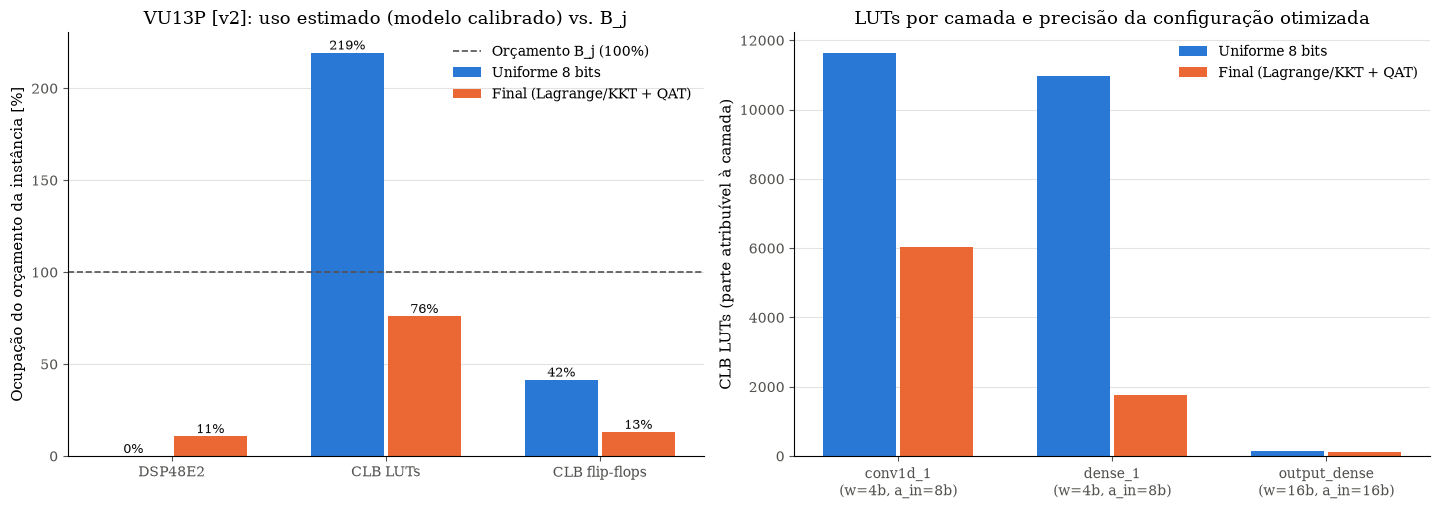

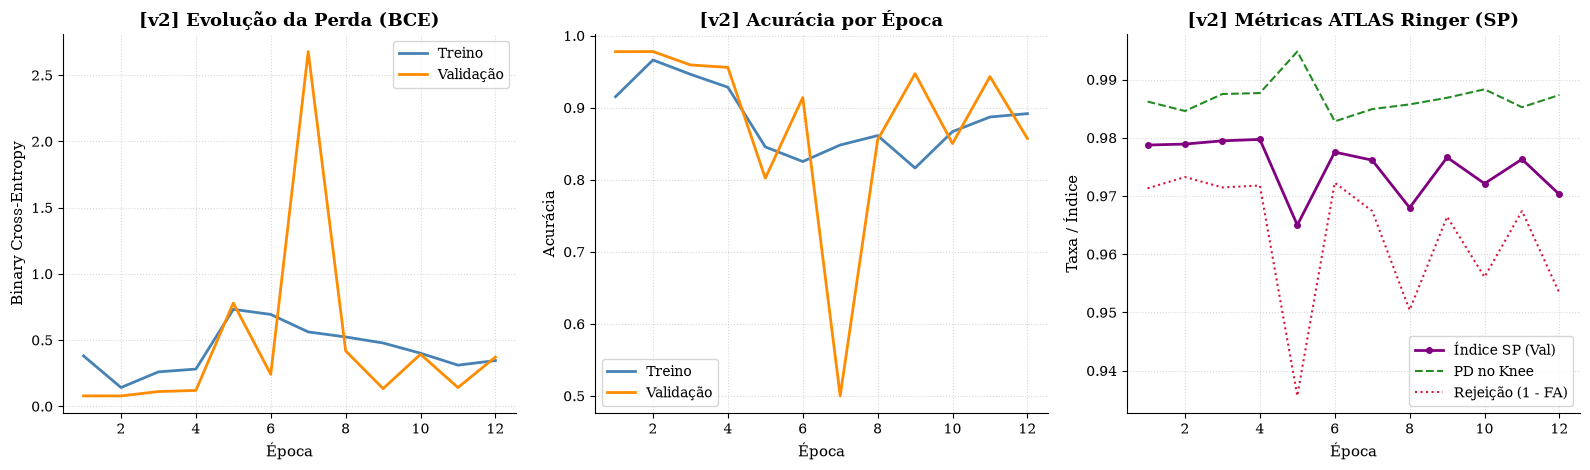

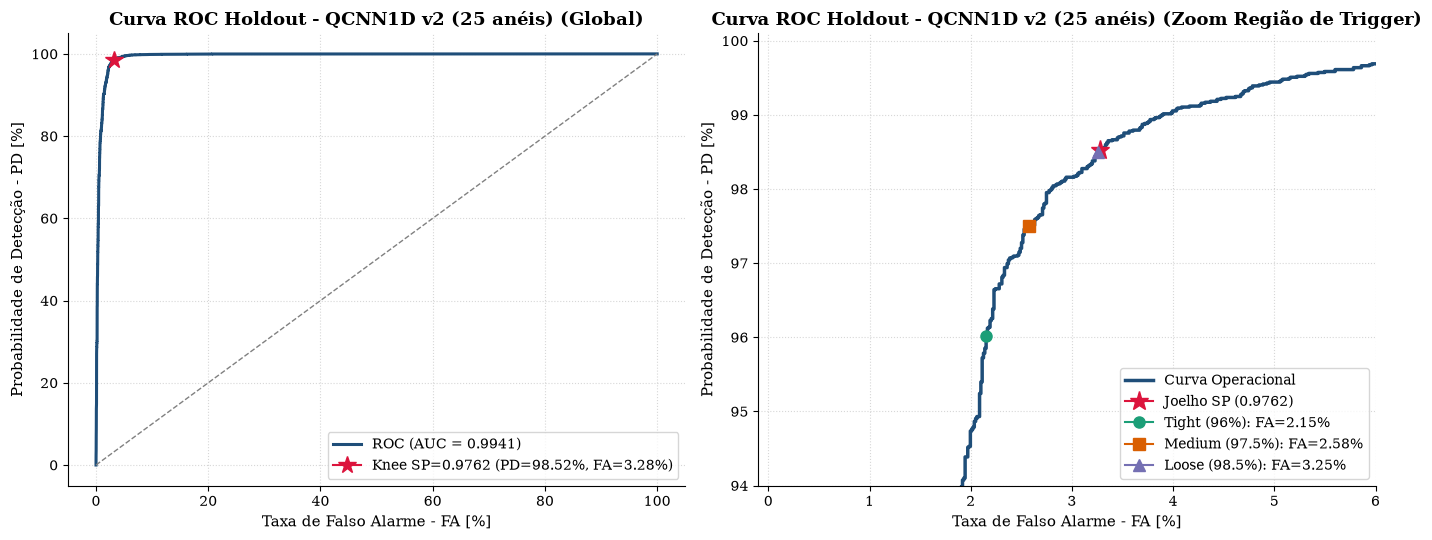

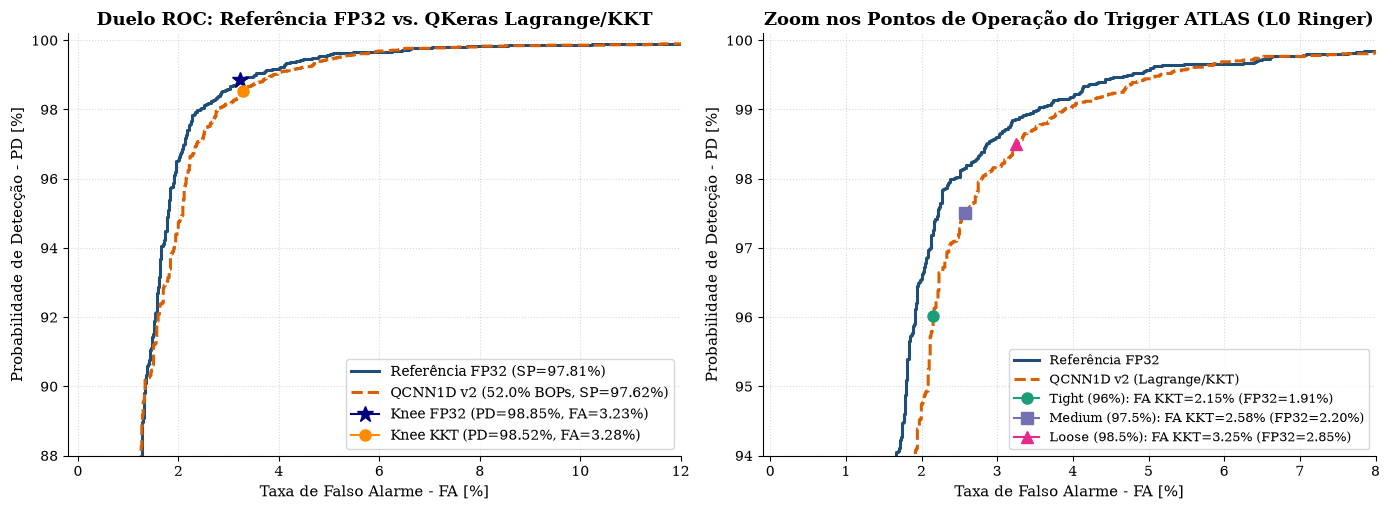

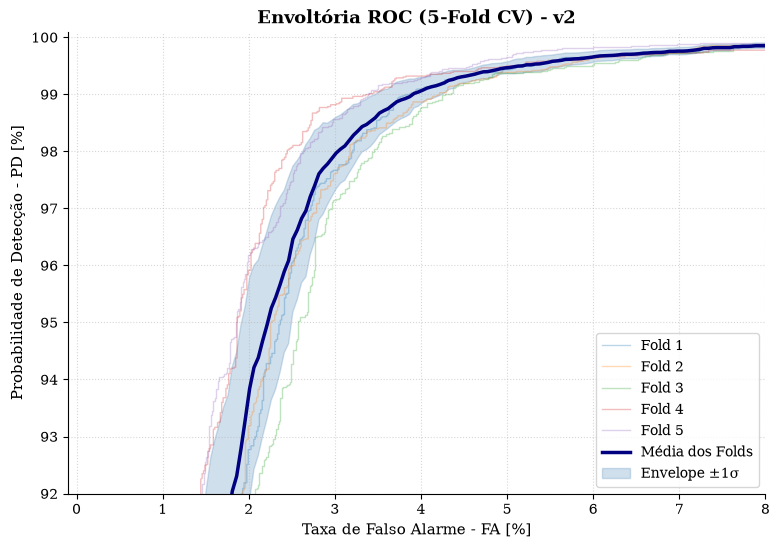

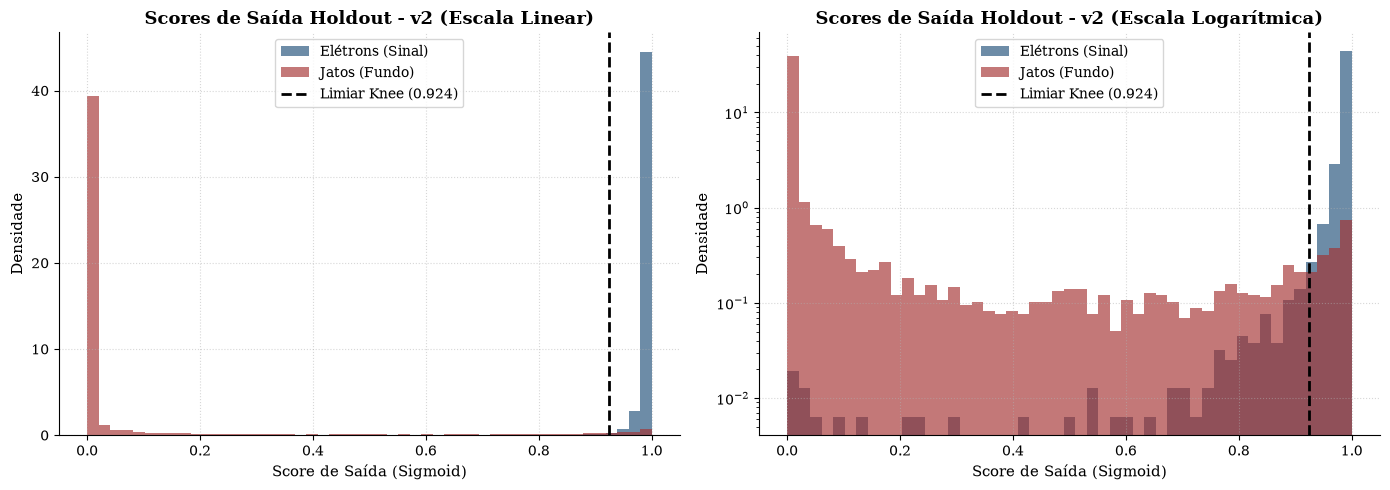

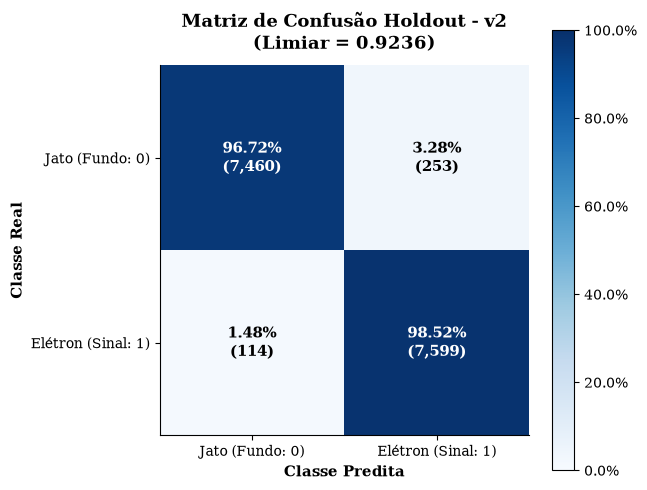

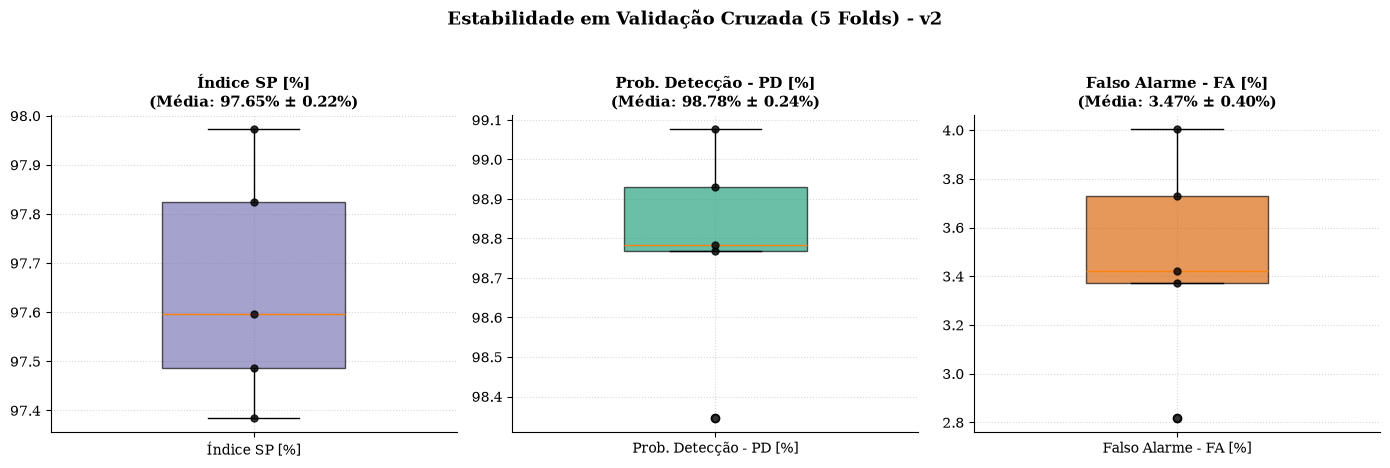

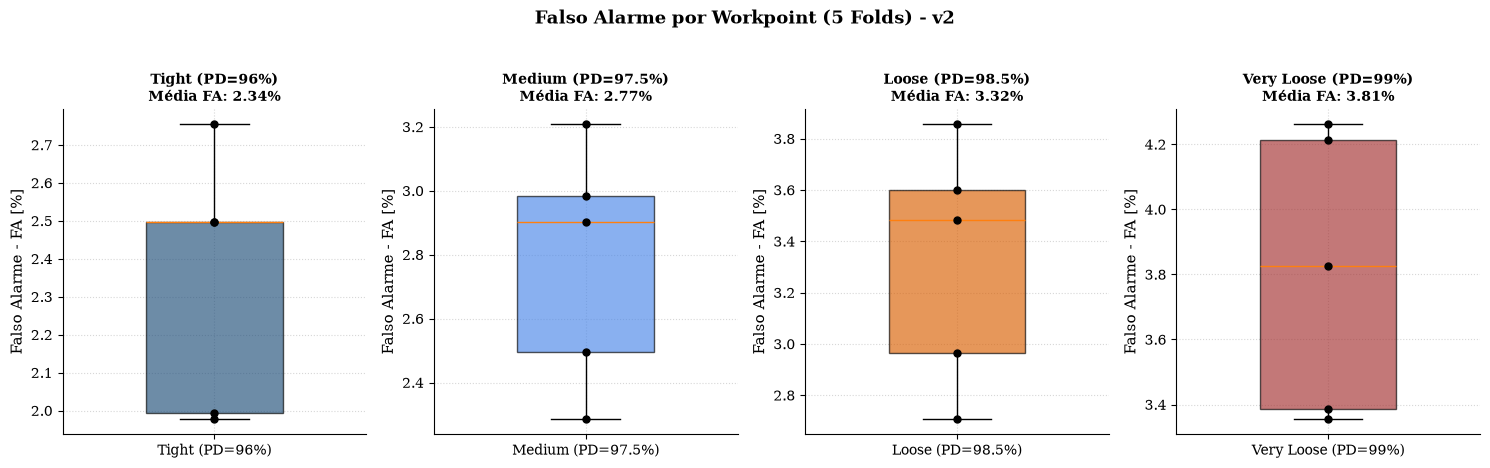

'/home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2/plots/fa_per_fold_workpoints.png'

In [9]:
plot_vu13p_resource_utilization(hw_u8, hw_final, B, save_path=exporter.get_plot_path("vu13p_resource_utilization.png"),
                                labels=("Uniforme 8 bits", "Final (Lagrange/KKT + QAT)"), title_prefix=f"VU13P [v{VERSION}]", show=True)
plot_learning_curves(history_dict=best["history"], save_path=exporter.get_plot_path("learning_curves.png"),
                     title_prefix=f"[v{VERSION}]", show=True)
plot_best_model_roc(y_true=y_holdout, y_pred=y_pred_holdout, sp_val=ho_q["sp"], pd_knee=ho_q["pd"], fa_knee=ho_q["fa"],
                    save_path=exporter.get_plot_path("roc_best_model.png"),
                    title=f"Curva ROC Holdout - QCNN1D v{VERSION} ({arch['input_dim']} anéis)", show=True)
plot_roc_duel_fp32_vs_kkt(y_val=y_holdout, y_pred_fp32=ho_fp32["y_pred"], sp_fp32=ho_fp32["sp"], pd_fp32=ho_fp32["pd"],
                          fa_fp32=ho_fp32["fa"], y_pred_q=y_pred_holdout, sp_q=ho_q["sp"], pd_q=ho_q["pd"], fa_q=ho_q["fa"],
                          bops_ratio=hw_final["total_bops"] / hw_u8["total_bops"],
                          save_path=exporter.get_plot_path("roc_duel_fp32_vs_kkt.png"), title_prefix=f"QCNN1D v{VERSION}", show=True)
plot_cv_roc_envelope(folds_y_true=folds_y_true, folds_y_pred=folds_y_pred, save_path=exporter.get_plot_path("roc_cv_envelope.png"),
                     title=f"Envoltória ROC ({N_SPLITS}-Fold CV) - v{VERSION}", show=True)
plot_output_score_histogram(y_true=y_holdout, y_pred=y_pred_holdout, threshold_knee=best["threshold"],
                            save_path=exporter.get_plot_path("output_scores_hist.png"), title=f"Scores de Saída Holdout - v{VERSION}", show=True)
plot_confusion_matrix_knee(y_true=y_holdout, y_pred=y_pred_holdout, threshold_knee=best["threshold"],
                           save_path=exporter.get_plot_path("confusion_matrix_knee.png"), title=f"Matriz de Confusão Holdout - v{VERSION}", show=True)
plot_cv_statistics_boxplots(cv_df=cv_df, save_path=exporter.get_plot_path("cv_boxplots.png"),
                            title=f"Estabilidade em Validação Cruzada ({N_SPLITS} Folds) - v{VERSION}", show=True)
plot_fa_per_fold_workpoints(folds_y_true=folds_y_true, folds_y_pred=folds_y_pred, save_path=exporter.get_plot_path("fa_per_fold_workpoints.png"),
                            title=f"Falso Alarme por Workpoint ({N_SPLITS} Folds) - v{VERSION}", show=True)


## 9. Tabelas finais

In [10]:
display(pd.DataFrame([{
    "Camada": b["layer_name"], "Tipo": b["layer_type"], "n_l": b["units"], "w_l": b["b_w"], "a_in,l": b["b_a_in"],
    "Parâmetros": b["params"], "MACs": b["macs"], "BOPs": b["bops"], "pesos ≠ 0 [%]": round(100 * b["nonzero_weight_frac"], 1),
    "DSP": round(b["DSP"]), "LUT": round(b["LUT"]), "FF": round(b["FF"])} for b in hw_final["breakdown"]]))

summary = []
for label, (wb, ab) in REFERENCES.items():
    key = (tuple(wb[n] for n in COMPUTE_LAYERS), tuple(ab[m] for m in ACTIVATION_LAYERS))
    row = df_qat[df_qat["_key"].apply(lambda k: k == key)]
    c = config_cost(wb, ab)
    summary.append({"Modelo": label, "w": list(key[0]), "a": list(key[1]),
                    "SP val (QAT)": f"{row['sp_val'].iloc[0]*100:.2f}%" if len(row) else "–",
                    **{r: f"{c[r]:,.0f}" for r in ("DSP", "LUT", "FF")}, "viável em B": is_feasible(c)})
summary.append({"Modelo": "Final (CV + holdout)", "w": [final_w[n] for n in COMPUTE_LAYERS], "a": [final_a[m] for m in ACTIVATION_LAYERS],
                "SP val (QAT)": f"{final_row['sp_val']*100:.2f}% | CV {cv_df['sp_max'].mean()*100:.2f}±{cv_df['sp_max'].std()*100:.2f}% | holdout {ho_q['sp']*100:.2f}%",
                **{r: f"{hw_final['vu13p_resources'][r]:,.0f}" for r in ("DSP", "LUT", "FF")}, "viável em B": is_feasible(hw_final["vu13p_resources"])})
summary.append({"Modelo": "FP32 (referência)", "w": "float", "a": "float",
                "SP val (QAT)": f"val {cb_fp32.best_sp*100:.2f}% | CV {cv_df['sp_fp32_ref'].mean()*100:.2f}±{cv_df['sp_fp32_ref'].std()*100:.2f}% | holdout {ho_fp32['sp']*100:.2f}%",
                "DSP": "–", "LUT": "–", "FF": "–", "viável em B": "–"})
summary[0]["SP val (QAT)"] += f" | CV {cv_df['sp_u8_ref'].mean()*100:.2f}±{cv_df['sp_u8_ref'].std()*100:.2f}%"
display(pd.DataFrame(summary))

print(f"\nÁrvore de artefatos: {exporter.base_dir}")
for root, dirs, files in os.walk(exporter.base_dir):
    level = root.replace(exporter.base_dir, "").count(os.sep)
    print(f"{'  ' * level}├── {os.path.basename(root) if level else f'v{VERSION}'}/")
    for f_name in sorted(files):
        print(f"{'  ' * (level + 1)}└── {f_name} ({os.path.getsize(os.path.join(root, f_name)) / 1024:.1f} KB)")


,Camada,Tipo,n_l,w_l,"a_in,l",Parâmetros,MACs,BOPs,pesos ≠ 0 [%],DSP,LUT,FF
0,conv1d_1,QConv1D,8,4,8,32,600,19200,75.0,0,6020,998
1,dense_1,QDense,8,4,8,776,768,24576,32.7,0,1767,677
2,output_dense,QDense,1,16,16,9,8,2048,100.0,8,106,97


,Modelo,w,a,SP val (QAT),DSP,LUT,FF,viável em B
0,u8 (8 bits uniforme),"[8, 8, 8]","[8, 8]",97.83% | CV 97.72±0.25%,0,"22,752","8,623",False
1,"KKT antigo [2,5,8]/[8,8]","[2, 5, 8]","[8, 8]",97.65%,0,"8,447","3,141",True
2,u16,"[16, 16, 16]","[16, 16]",–,"1,222","25,177","16,548",False
3,Final (CV + holdout),"[4, 4, 16]","[8, 16]",97.67% | CV 97.65±0.24% | holdout 97.62%,8,"7,893","2,728",True
4,FP32 (referência),float,float,val 97.80% | CV 97.61±0.25% | holdout 97.81%,–,–,–,–



Árvore de artefatos: /home/felipe/cern/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2
├── v2/
  ├── evaluation/
    └── holdout_predictions.npz (53.9 KB)
    └── holdout_test_set.npz (1016.9 KB)
  ├── history/
    └── history.json (2.4 KB)
    └── training_history.csv (1.9 KB)
  ├── saved_models/
    └── best_model.h5 (53.9 KB)
    └── best_model.keras (52.3 KB)
    └── best_model.onnx (0.7 KB)
    └── model_v2_f1_r1.h5 (53.9 KB)
    └── model_v2_f1_r1.keras (52.3 KB)
    └── model_v2_f2_r1.h5 (53.9 KB)
    └── model_v2_f2_r1.keras (52.3 KB)
    └── model_v2_f3_r1.h5 (53.9 KB)
    └── model_v2_f3_r1.keras (52.3 KB)
    └── model_v2_f4_r1.h5 (53.9 KB)
    └── model_v2_f4_r1.keras (52.3 KB)
    └── model_v2_f5_r1.h5 (53.9 KB)
    └── model_v2_f5_r1.keras (52.3 KB)
  ├── plots/
    └── confusion_matrix_knee.png (147.3 KB)
    └── cv_boxplots.png (221.9 KB)
    └── fa_per_fold_workpoints.png (277.8 KB)
    └── kkt_primal_dual_evolution.png (359.6 KB)
   